# Does a half-known word map learned on 24 keys carry to 8 unseen keys, and does VPD agree?

*E58, 2026-10-30. Record and full tables: `reports/analyses/2026-10-30_analysis_e58-open-pair.md`. Plan:
`reports/plans/2026-10-30_plan_e58-open-pair.md`. Words as in `GOALS.md` → Terms.*

## The answer

No carry-over by the filed measure, and the decomposition reads the opposite. Trained on 24 keys, the half-known map's
answers at the 8 unseen keys rose far less than at the trained keys. They also rose less than the trained answers did at
those same unseen keys, so the value-specific gain there is slightly negative, on all three seeds. The arbitrary control
map reads the same, as it must. Yet switching on
existing subcomponents still carries about three quarters of the half-known map's gain, as when every key was trained.
So a filed prediction, that the two would agree, failed. Our reading: the values are words the model already says after
these keys, so the subcomponents are old while the lookup is new.

In [1]:
import json
from pathlib import Path

from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXP = ROOT / "experiments" / "open_pair"
RUN = json.loads((EXP / "results" / "run.json").read_text())
ST, SC = RUN["states"], RUN["score"]
# figures: experiments/open_pair/plot.py, from run.json only
print("stage-0 controls passed:", RUN["stage0"]["pass"], "| elicit labels:", SC["P0"]["labels"],
      "| cipher labels:", SC["P1"]["labels"])

stage-0 controls passed: True | elicit labels: ['new', 'new', 'new'] | cipher labels: ['new', 'new', 'new']


## What we were trying to test

The re-gating line asks whether a VPD decomposition can tell a fine-tune that strengthens something the model already
does from one that teaches something new. Its numbers have only been scored against labels fixed by how each task was
built. Here the label comes from behaviour alone.

**The task.** Each window is Pile text, then a rare marker token, then a key word; the model must predict the key's
value next. Two maps share the 32 keys and the windows. In the *elicit map*, each value is a word the original model W₀
already ranks 2nd to 20th after that key, such as " formed" → " from". In the *cipher*, the values are arbitrary words
W₀ almost never gives there. The cipher's unseen values cannot be guessed from its trained ones, so it is the label's
negative control.

**What changed.** E54's fine-tune recipe ran on only 24 of the 32 keys, three seeds per map. The other 8 keys never sat
at a training window's key position. The elicit map is read at step 10, when the trained keys are learned. The cipher is
read at the step whose total weight change matches the elicit state's.

**The label.** For a window, the *specific gain* is the fine-tune's rise in the log-odds of the window's own value, minus
the mean rise of the map's other 31 values. Subtracting them removes a shift shared by the whole value set. A first,
stopped job found such a shift on E54's cipher. The trained-key gain $G_\text{spec}$ is the mean specific gain on
unused windows of the trained keys. The held-out gain $H_\text{spec}$ is the same on the 8 held-out keys, and
$x = H_\text{spec} / G_\text{spec}$. At 0 the unseen keys gained
nothing; at 1 they gained as much as the trained ones. The label is "reuses" if $x \ge 0.5$ and "new" if $x$ is at or below
three bootstrap standard deviations $s$.

**The readings**, E54's, on the least-squares split of each weight change:

- $r$, the share of the fine-tune's gain recovered when the subcomponents stay at W₀'s and only Γ's CI values change. It
  reads 1 if switching existing subcomponents on carries all the gain.
- The *stand-in ratio*, the CI-masked model's gain over the gain of the split subcomponents with every mask open. It is
  roughly the gain from Γ's new CI values over the subcomponent gain, not "the share Γ keeps", and has no ceiling at 1.
- $S$, steering's share: one mean vector added at one block. It never reads the decomposition.

Each reading says "reuses" at 0.5 or more.

## What we expected, and why

We left the elicit label open, at about even odds for "reuses": if the fine-tune sharpened what W₀ already prefers after
each key, unseen keys would gain too. Every cipher had to read "new". We expected r and the stand-in ratio to stay high
on the elicit map, as in E54, so the prediction that they agree with the label would pass exactly when the label read
"reuses". We also expected both readings to separate the elicit map from the cipher again.

## Did the fine-tune carry over to the keys it never saw?

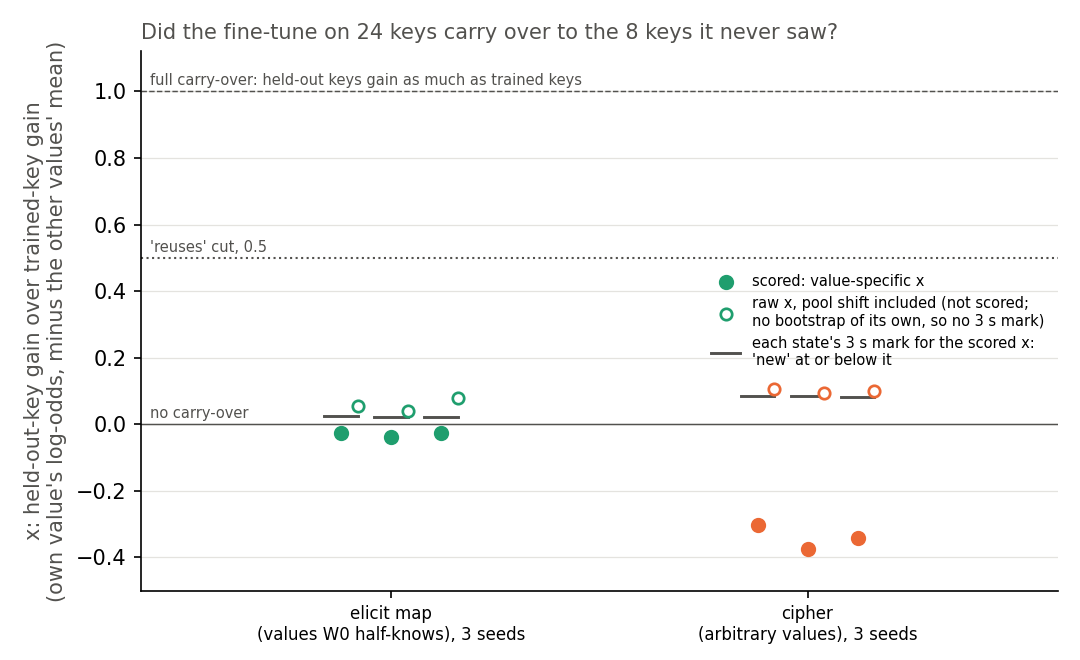

In [2]:
display(Image(filename=str(EXP / "figures" / "label.png")))

In [3]:
rows = ["| state | trained-key gain | held-out gain | x | label |", "|---|---|---|---|---|"]
for t in ("elicit", "cipher"):
    for s in (0, 1, 2):
        d = ST[f"{t}_s{s}"]
        rows.append(f"| {t}, seed {s} | {d['G_spec']:.2f} | {d['H_spec']:.2f} | {d['x']:.3f} | {d['label']} |")
display(Markdown("\n".join(rows)))

| state | trained-key gain | held-out gain | x | label |
|---|---|---|---|---|
| elicit, seed 0 | 18.18 | -0.50 | -0.027 | new |
| elicit, seed 1 | 18.43 | -0.70 | -0.038 | new |
| elicit, seed 2 | 18.51 | -0.48 | -0.026 | new |
| cipher, seed 0 | 10.67 | -3.24 | -0.303 | new |
| cipher, seed 1 | 9.39 | -3.54 | -0.377 | new |
| cipher, seed 2 | 9.94 | -3.40 | -0.342 | new |

**Reading it.** No. On all three elicit seeds the held-out keys' specific gain was slightly negative, so $x$ sits just
below 0 and the label is "new". The trained keys gained about 18 log-odds on the same measure. The cipher reads "new"
too, further below 0, so the negative control passed. The hollow points keep the shared shift in and read 0.04 to 0.08
for the elicit map, far from the cut; they have no bootstrap of their own, so no label. Resampling the 8 keys instead of windows changes no label.

## Was carry-over possible, or did the task rule it out?

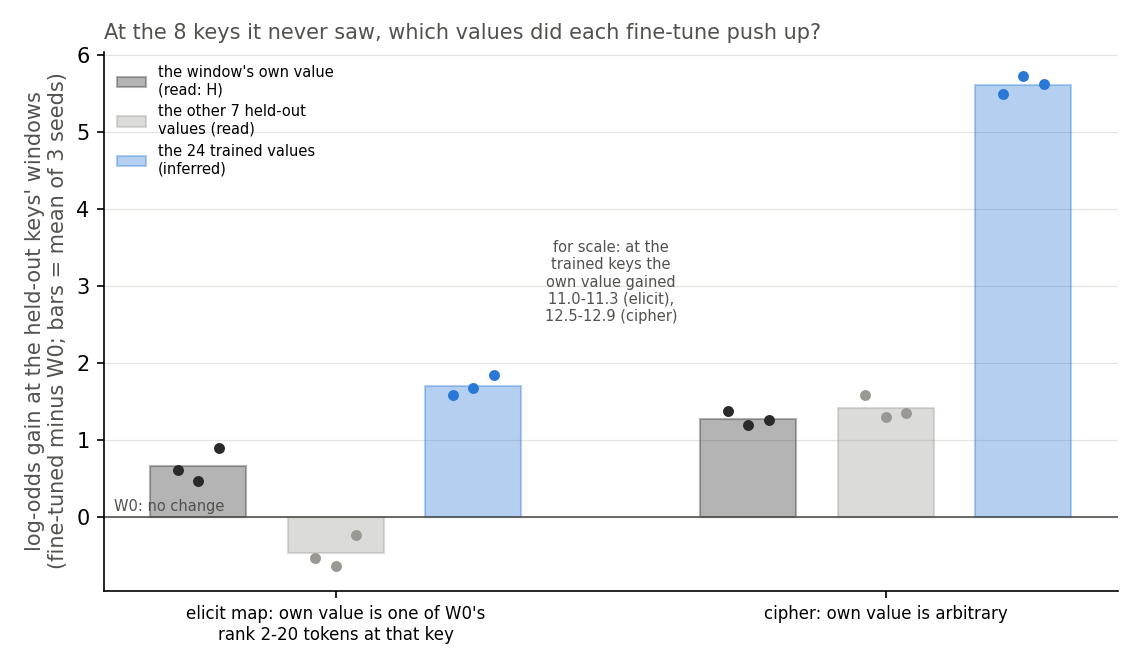

In [4]:
display(Image(filename=str(EXP / "figures" / "heldout_gain.png")))

**Reading it.** Carry-over was possible, and the fine-tune took that route only weakly. There is no rule from key to
value here, so the one way unseen keys could gain is a general sharpening of what W₀ already prefers after each key.
That would raise the held-out key's own value most. The own value rose by about 0.6 log-odds, while the 24 trained values
rose by about 1.7. The trained values' rise is inferred, not read: it follows from three read means, since the 32 values
are distinct.

That push hides a small key-specific boost. Against its 7 held-out siblings, the own value gained about 1.1 more on the
elicit map, and about 0.1 to 0.2 less on the cipher. Each contrast comes from two read means. The boost is about 6% of the
trained keys' specific gain. So the update is mostly 24 lookups plus a push toward the trained values, with a small
key-specific boost. The rank-k readout, next, tests that boost directly; the label stands as filed.

In [5]:
rows = ["| state | own value | 7 held-out siblings | own minus siblings |", "|---|---|---|---|"]
for t in ("elicit", "cipher"):
    for s in (0, 1, 2):
        d = ST[f"{t}_s{s}"]
        rows.append(f"| {t}, seed {s} | {d['H']:+.2f} | {d['H_other']:+.2f} | {d['H'] - d['H_other']:+.3f} |")
display(Markdown("\n".join(rows)))

| state | own value | 7 held-out siblings | own minus siblings |
|---|---|---|---|
| elicit, seed 0 | +0.61 | -0.53 | +1.145 |
| elicit, seed 1 | +0.46 | -0.64 | +1.098 |
| elicit, seed 2 | +0.90 | -0.23 | +1.127 |
| cipher, seed 0 | +1.38 | +1.58 | -0.208 |
| cipher, seed 1 | +1.19 | +1.29 | -0.105 |
| cipher, seed 2 | +1.26 | +1.35 | -0.095 |

*Gains at the held-out keys' windows, log-odds, fine-tuned minus W₀.*

## Do the decomposition's readings agree with the label?

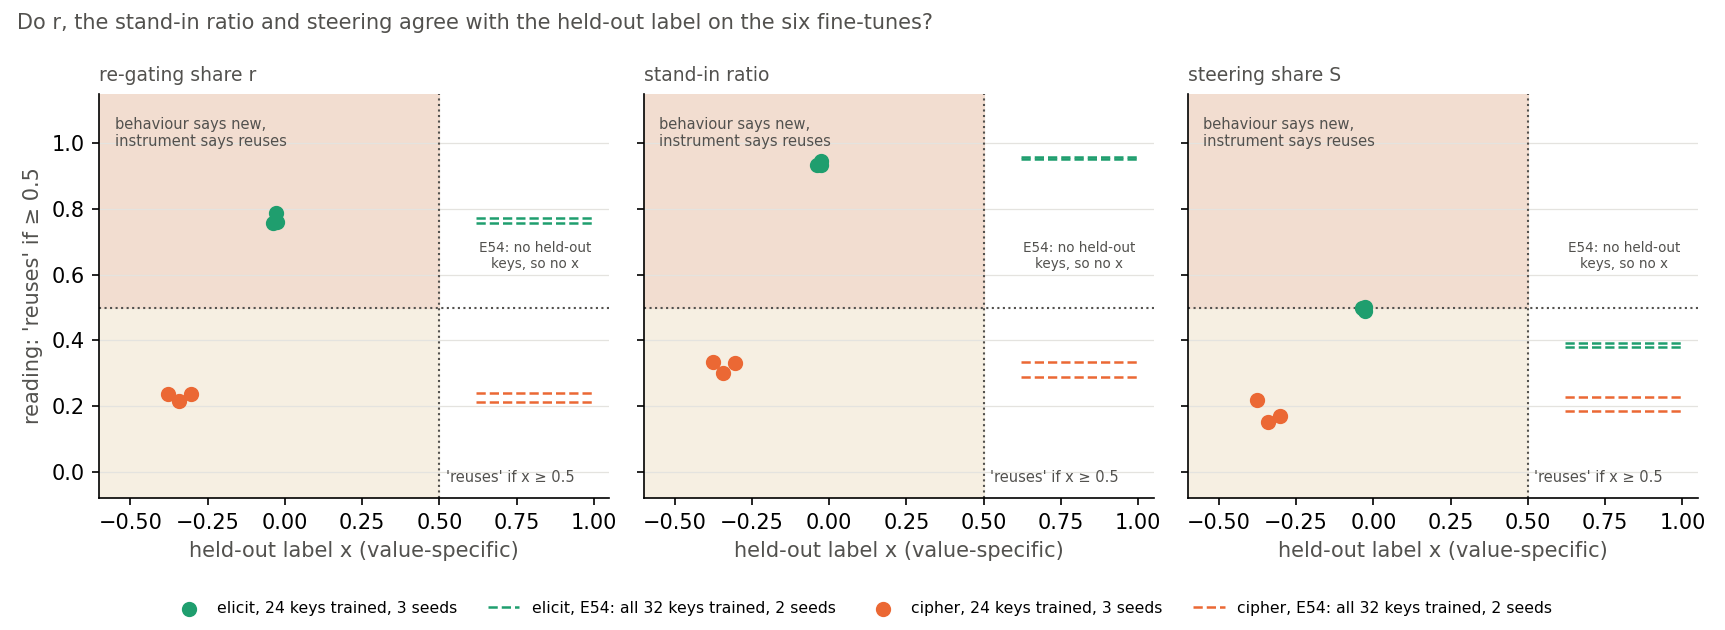

In [6]:
display(Image(filename=str(EXP / "figures" / "agreement.png")))

In [7]:
rows = ["| state | r | stand-in ratio | steering S | label |", "|---|---|---|---|---|"]
for t in ("elicit", "cipher"):
    for s in (0, 1, 2):
        d = ST[f"{t}_s{s}"]
        rows.append(f"| {t}, seed {s} | {d['r']:.3f} | {d['ratio']:.3f} | {d['S']:.3f} | {d['label']} |")
display(Markdown("\n".join(rows)))

| state | r | stand-in ratio | steering S | label |
|---|---|---|---|---|
| elicit, seed 0 | 0.787 | 0.946 | 0.501 | new |
| elicit, seed 1 | 0.757 | 0.934 | 0.498 | new |
| elicit, seed 2 | 0.758 | 0.934 | 0.490 | new |
| cipher, seed 0 | 0.236 | 0.330 | 0.171 | new |
| cipher, seed 1 | 0.238 | 0.336 | 0.220 | new |
| cipher, seed 2 | 0.217 | 0.302 | 0.152 | new |

**Reading it.** No: r and the stand-in ratio read "reuses" on every elicit state, while the label reads "new". The
green points sit in the upper-left box of the first two panels, level with E54's values for the same map with all keys
trained. Both readings still separate the elicit map from the cipher: r by 0.54 and the ratio by 0.62. Seed ranges are near 0.03.

Steering agrees with the label on more states, but that is not a finding. Its three elicit values are 0.50, 0.50 and
0.49, on its own cut, so it scores by sitting on the line. We keep it out of the headline.

## What we learned

This is the lead's reading, not a proof: no check here separates it from "the decomposition is wrong".

VPD's unit is the rank-one subcomponent, so a new lookup built from old subcomponents, switched on in a new pattern,
reads "elicited" to r and the stand-in ratio. Here the elicit values are words W₀ already says after these keys, so the
subcomponents that write them exist; the cipher's do not, and its readings are low. The held-out label asks a
different question: does a rule carry to unseen inputs? On a lookup over existing words those two answers can differ,
and they do here, on three seeds each way. Every claim holds only at the level of VPD's subcomponents.

For `GOALS.md`, under the adopted reading, with ask #14 still open, r and the ratio can be scored against a behavioural label only on tasks where "reuses" means a rule W₀
already has. We ask the user, as ask #14, which meaning the line uses. Under A, "built from existing subcomponents", r
did its job. Under B, "generalises to unseen inputs", E58 counts against VPD. The lead proceeds with A.

## How compelling is the evidence

Three fine-tune seeds per map, one key split, one decomposition. The label's real unit is the 8 held-out keys, and it
holds when keys are resampled. The label is blind to a carry-over that raises every value alike. No positive control
for it exists yet on this model: the cipher shows it can read "new", nothing shows it can read "reuses". The readings
reproduced E54 to four decimals before any fine-tune.

## Surprises

- A filed prediction failed: the decomposition's labels disagree with the behavioural label on every elicit state. It
  was filed at about even odds, so this is a failure as filed, not a reversal of a confident lean.
- Steering's share on the elicit map rose to about 0.5 with 24 keys, from about 0.39 with all 32. We assert no cause.
- At unseen keys the cipher pushes its trained values up by about 5.6 log-odds, three times the elicit map's push.

## What next

- **The label's positive control**, at no cost: a map whose rule W₀ already has, such as each key's top word. If it reads
  "reuses", its r is the line's first state labelled reuse by behaviour. If not, the bar is out of reach here.
- **The W₀ rank-k readout** on the six saved states. If W₀'s top-20 words at a held-out key all rise with rank, the
  update partly sharpens W₀ after all; if only the trained values rise, the lookup reading holds.
- **The user's answer to ask #14** sets whether the agreement test is scored on rule tasks only.

## Scorecard

| id | claim | read | verdict |
|---|---|---|---|
| P0 | the elicit label, a lean toward "reuses" | new ×3 | new; lean missed |
| P1 | every cipher reads "new" | new ×3 | pass |
| P2 | r's and the ratio's labels equal the behavioural label | reuses ×3 vs new ×3 | **fail**, both |
| P3 | the decomposition agrees with the label more often than steering | r 3, ratio 3, S 5 of 6 | "steering_better" as scored; not a finding, S on its cut |
| P4 | r and the ratio separate elicit from cipher, as E54 | gaps 0.54, 0.62; ranges 0.03 | pass, both |

## Departures from the literature

- The bar is the reuse line's Stage B rule, from Jain et al.'s Definition 2 with the user's bounded g. Stage B reads the
  share an interchange patch carries; here it is read on behaviour only, with no patch.
- The gain is value-specific, the map's other values' mean gain subtracted, filed before any fine-tune.
- The bootstrap resamples windows, which share keys, where Stage B resamples independent texts; a key-level bootstrap is
  reported and changes no label.
- The 0.5 cut on the stand-in ratio copies E12's rule for r; the ratio has no ceiling at 1, so the cut is a convention.
- The gate on the trained-key gain was lowered from 8 to 5.148 before any fine-tune, keeping Fable's fraction of E54's
  gain; every elicit state cleared it by more than three times.

## Not run

The W₀ rank-k readout and the label's positive control, both E58 Amendment 1, next. The novelty column on Γ's CI
patterns. The interchange patch. More key splits, seeds or decomposition seeds; the cipher at its own step; Qwen.

## Provenance

Job 46266, MATS `debug`, one L40, $0, about 3 minutes; code `b11a921`, results commit `16f43d6`. Stopped stage-0 job
46259, results commit `080b1f2`. Weight changes and log in `~/commute-data/results-large/open_pair/`.